# Part 4: Forecast maps vs observed maps

Station values are interpolated to the 0.05° Bihar grid with inverse-distance weighting (power 2, all stations).

**Model shown:** the final Part 2 model (Sanath's Laplace linear model on `log1p`, smeared mean; validation forecasts in `preds/sanath_laplace_mean.parquet`), next to persistence and the Part 1 ridge.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import baseline as B

np.random.seed(0)
warnings.filterwarnings("ignore")

MODEL_NAME = "Laplace (Part 2)"   # label used in titles and tables
MODEL_PATH = "preds/sanath_laplace_mean.parquet"   # final Part 2 model (Sanath)
# --------------------------------------------------------------------

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

W, stations = B.load_data()
_, T_val = B.issue_times()
T_tgt = T_val + pd.Timedelta(hours=24)     # 91 noon targets, 1 Sep - 30 Nov
dates = T_tgt.normalize()
grid = pd.read_csv("data/bihar_grid_005deg.csv")
boundary = pd.read_csv("data/bihar_boundary.csv")
print(len(T_tgt), "validation days;", len(grid), "grid cells;", len(stations), "stations")

91 validation days; 3396 grid cells; 468 stations


IDW interpolator (power 2, all stations)

In [2]:
gx = (grid.longitude.to_numpy() - 85.5) * 100.3
gy = (grid.latitude.to_numpy() - 25.7) * 110.6
sxy = stations[["x_km", "y_km"]].to_numpy()
D = np.sqrt((gx[:, None] - sxy[None, :, 0]) ** 2 + (gy[:, None] - sxy[None, :, 1]) ** 2)   # 3396 x 468, km

EPS = 1e-6
Wt = 1.0 / np.maximum(D, EPS) ** 2
on_station = D.min(axis=1) < EPS                      # grid cell sits on a station: use it exactly
Wt[on_station] = (D[on_station] < EPS).astype(float)
Wt /= Wt.sum(axis=1, keepdims=True)

def idw(V):
    """V: (..., 468) station values -> (..., 3396) grid values."""
    return np.asarray(V) @ Wt.T

print("Cells exactly on a station:", int(on_station.sum()))

Cells exactly on a station: 0


Map helper


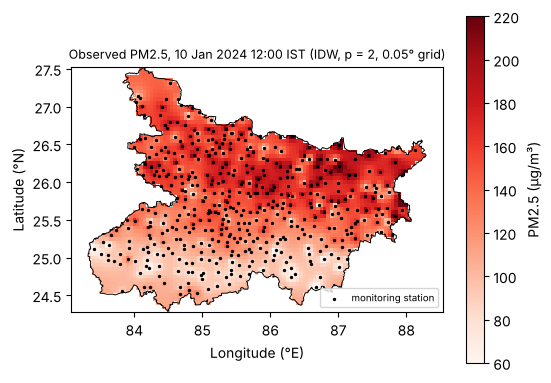

In [3]:
lons = np.round((grid.longitude.to_numpy() - grid.longitude.min()) / 0.05).astype(int)
lats = np.round((grid.latitude.to_numpy() - grid.latitude.min()) / 0.05).astype(int)
lon_axis = grid.longitude.min() + 0.05 * np.arange(lons.max() + 1)
lat_axis = grid.latitude.min() + 0.05 * np.arange(lats.max() + 1)

def to_mesh(m):
    Z = np.full((len(lat_axis), len(lon_axis)), np.nan)
    Z[lats, lons] = m
    return Z

def draw(ax, m, title, vmin, vmax, cmap="Reds"):
    h = ax.pcolormesh(lon_axis, lat_axis, to_mesh(m), cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    ax.plot(boundary.longitude, boundary.latitude, "k-", lw=0.7)
    ax.scatter(stations.longitude, stations.latitude, s=2, c="k", label="monitoring station")
    ax.set_title(title, fontsize=9); ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
    ax.set_aspect(1.0 / np.cos(np.deg2rad(25.7)))
    return h

# Figure-1 style check: observed 10 Jan 2024 12:00 (training period)
t0 = pd.Timestamp("2024-01-10 12:00")
fig, ax = plt.subplots(figsize=(6, 4.5))
h = draw(ax, idw(W.loc[t0].to_numpy()), "Observed PM2.5, 10 Jan 2024 12:00 IST (IDW, p = 2, 0.05° grid)", 60, 220)
fig.colorbar(h, ax=ax, label="PM2.5 (µg/m³)"); ax.legend(loc="lower right", fontsize=7)
plt.show()

 Station-level arrays (91 days x 468 stations)

In [4]:
n_days = len(T_val)
OBS = W.loc[T_tgt].to_numpy()                                   # observed at target
PERS = B.persistence(W, T_val).reshape(n_days, 468)             # reading at issue time

def load_preds(path):
    p = pd.read_parquet(path)
    p.index = pd.to_datetime(p.index).normalize()   # files may label rows 12:00; compare by date
    p.columns = p.columns.astype(str)
    assert p.shape == (n_days, 468), p.shape
    assert list(p.columns) == list(stations.index), "columns must be sensor_id in bihar_stations.csv order"
    assert (p.index == dates).all(), "rows must be the 91 target dates 1 Sep - 30 Nov"
    return np.clip(p.to_numpy(dtype=float), 0, None)

RIDGE = B.part1_ridge_predict(W, stations, T_val).reshape(n_days, 468)
MODEL = RIDGE if MODEL_PATH is None else load_preds(MODEL_PATH)

Metrics: station RMSE, map RMSE, pattern correlation (every validation day)

In [5]:
def daily_metrics(pred):
    Om, Fm = idw(OBS), idw(pred)
    st = np.sqrt(((np.clip(pred, 0, None) - OBS) ** 2).mean(axis=1))
    mp = np.sqrt(((Fm - Om) ** 2).mean(axis=1))
    pc = np.array([np.corrcoef(Fm[i], Om[i])[0, 1] for i in range(len(Om))])
    return pd.DataFrame({"station_rmse": st, "map_rmse": mp, "pattern_corr": pc}, index=dates)

candidates = {"Persistence": PERS, "Ridge (Part 1)": RIDGE}
if MODEL_PATH is not None:
    candidates[MODEL_NAME] = MODEL

daily = {k: daily_metrics(v) for k, v in candidates.items()}
# show only persistence, ridge and the chosen model (MODEL_NAME)
shown = ["Persistence", "Ridge (Part 1)"] + ([MODEL_NAME] if MODEL_NAME not in ("Persistence", "Ridge (Part 1)") else [])
summary = pd.DataFrame({k: {
    "overall station RMSE": np.sqrt(((np.clip(candidates[k], 0, None) - OBS) ** 2).mean()),
    "mean daily station RMSE": d.station_rmse.mean(),
    "mean daily map RMSE": d.map_rmse.mean(),
    "mean pattern corr": d.pattern_corr.mean()} for k, d in daily.items()}).T.round(3)
summary = summary.loc[shown]
assert abs(summary.loc["Persistence", "overall station RMSE"] - 32.75) < 0.01
assert abs(summary.loc["Ridge (Part 1)", "overall station RMSE"] - 29.58) < 0.01
assert not any(d.isna().any().any() for d in daily.values())


## Task 1
Pick three validation days: one clean, one polluted, and the one where your model’s station RMSE was worst. For each, plot side by side: the observed map, your forecast map, the persistence map, and the map of (your forecast−observed). Draw stations and the state outline on top, with one shared colourscale and units.

### Selecting the three days.

In [6]:
net_mean = pd.Series(OBS.mean(axis=1), index=dates)
model_daily = daily[MODEL_NAME] if MODEL_NAME in daily else daily_metrics(MODEL)

picks = {"clean": net_mean.idxmin(), "polluted": net_mean.idxmax(), "worst": model_daily.station_rmse.idxmax()}
pd.DataFrame({k: {"date": d.date(), "network mean obs": net_mean[d], "model station RMSE": model_daily.station_rmse[d],
                  "persistence station RMSE": daily["Persistence"].station_rmse[d]} for k, d in picks.items()}).T.round(2)

,date,network mean obs,model station RMSE,persistence station RMSE
clean,2024-09-15,7.890449,16.064987,27.282976
polluted,2024-11-27,174.969209,63.232641,71.668258
worst,2024-11-29,76.632521,82.314321,112.006204


### Side-by-side maps: observed | forecast | persistence | forecast - observed
The three PM2.5 panels share one colour scale; the difference panel has its own symmetric scale (levels and errors are different quantities).

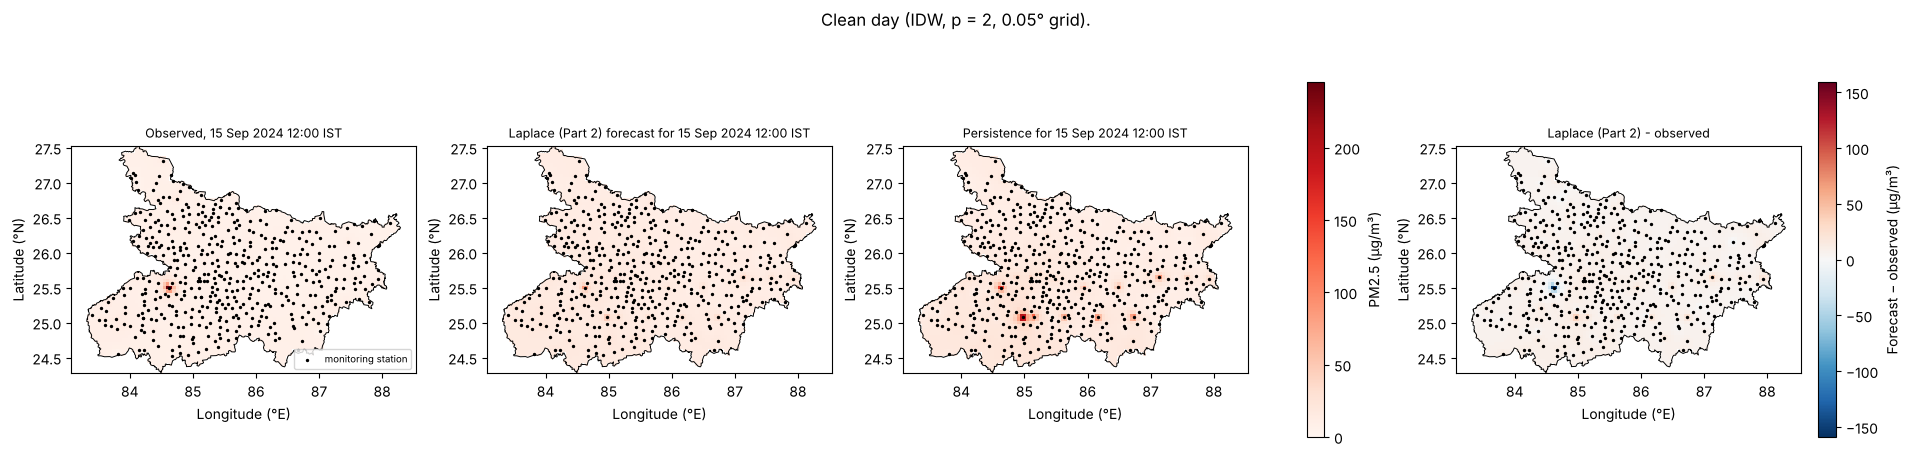

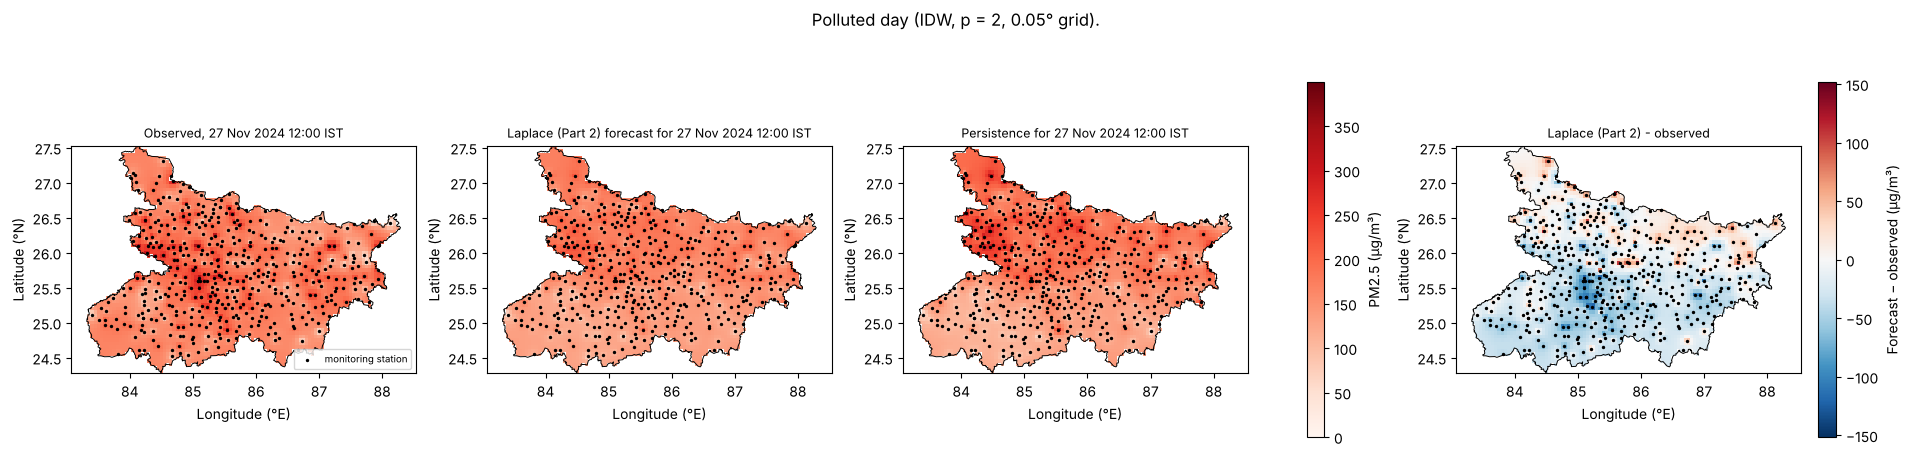

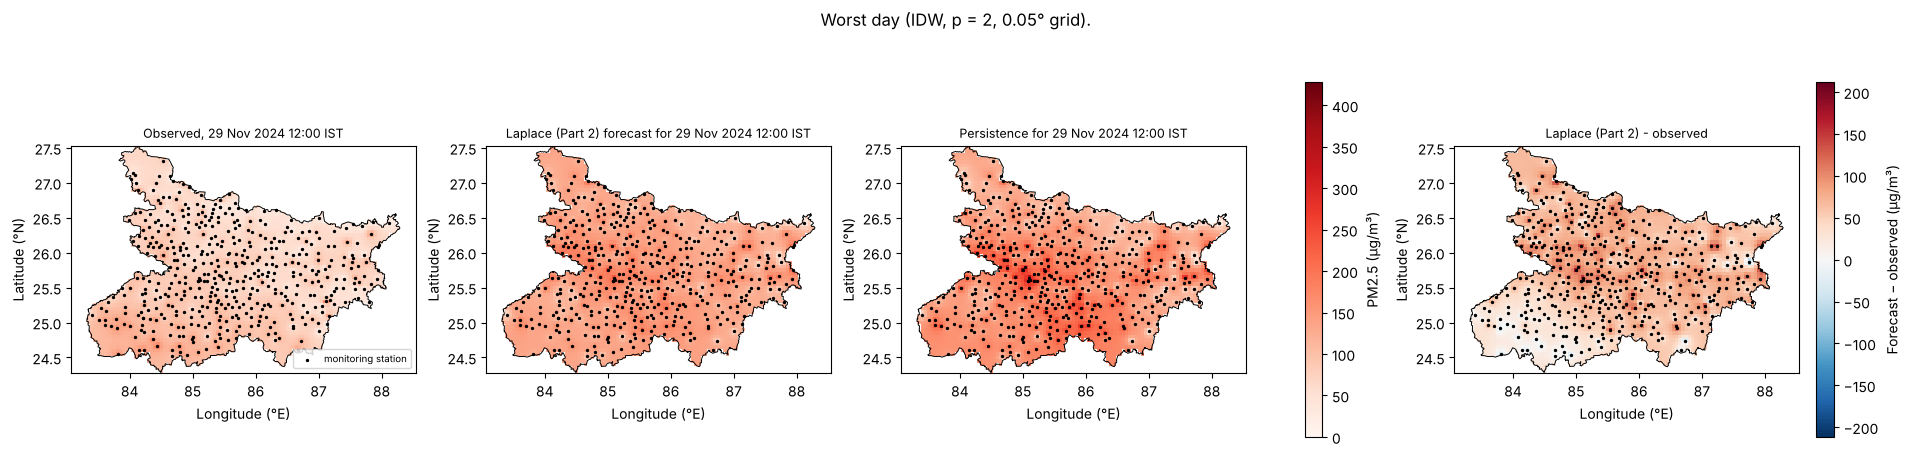

In [7]:
def plot_day(date, tag):
    i = int(np.where(dates == date)[0][0])
    O, F, P = idw(OBS[i]), idw(MODEL[i]), idw(PERS[i])
    vmax = max(np.nanmax(O), np.nanmax(F), np.nanmax(P)); vmin = 0
    dmax = np.nanmax(np.abs(F - O))
    day = f"{date:%d %b %Y} 12:00 IST"
    fig, axs = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
    draw(axs[0], O, f"Observed, {day}", vmin, vmax)
    h = draw(axs[1], F, f"{MODEL_NAME} forecast for {day}", vmin, vmax)
    draw(axs[2], P, f"Persistence for {day}", vmin, vmax)
    hd = draw(axs[3], F - O, f"{MODEL_NAME} - observed", -dmax, dmax, cmap="RdBu_r")
    fig.colorbar(h, ax=axs[:3], label="PM2.5 (µg/m³)", shrink=0.8)
    fig.colorbar(hd, ax=axs[3], label="Forecast − observed (µg/m³)", shrink=0.8)
    axs[0].legend(loc="lower right", fontsize=7)
    fig.suptitle(f"{tag.capitalize()} day (IDW, p = 2, 0.05° grid).")
    fig.savefig(FIG_DIR / f"part4_{tag}.png", dpi=150)
    plt.show()

for tag, d in picks.items():
    plot_day(d, tag)

## Task 2
For every validation day, compute: (a) map RMSE, the grid-cell difference between forecast and observed maps; (b) pattern correlation,the correlation across grid cells between the two maps. Report the averages for persistence and for your model, next to their station
RMSE.

### Metrics for every validation day:

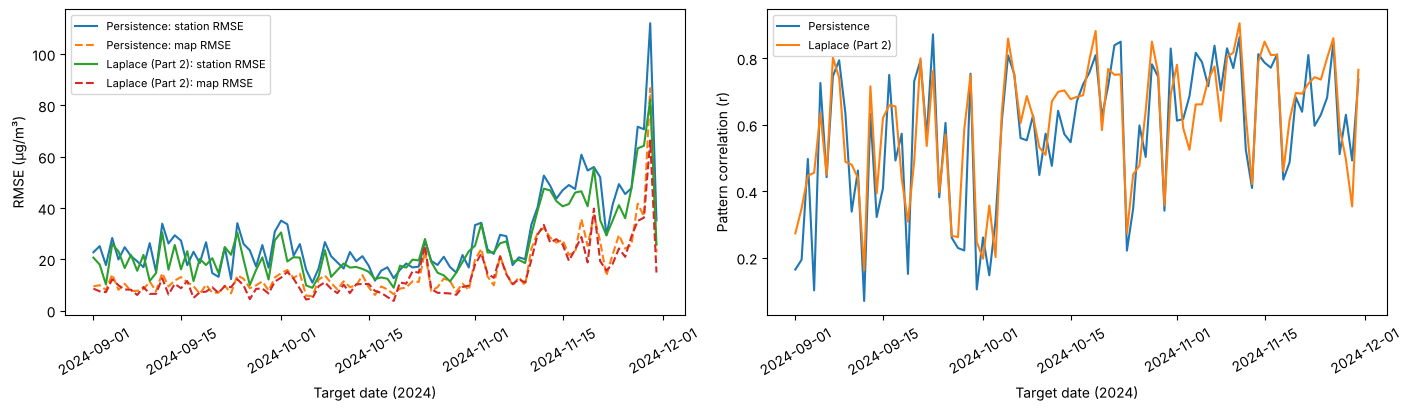

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for name in ["Persistence", MODEL_NAME]:
    d = daily[name] if name in daily else model_daily
    axs[0].plot(d.index, d.station_rmse, label=f"{name}: station RMSE")
    axs[0].plot(d.index, d.map_rmse, "--", label=f"{name}: map RMSE")
    axs[1].plot(d.index, d.pattern_corr, label=name)
axs[0].set_ylabel("RMSE (µg/m³)"); axs[0].legend(fontsize=8)
axs[1].set_ylabel("Pattern correlation (r)"); axs[1].legend(fontsize=8)
for a in axs: a.set_xlabel("Target date (2024)"); a.tick_params(axis="x", rotation=30)
fig.savefig(FIG_DIR / "part4_daily_metrics.png", dpi=150); plt.show()

### Comparison:

In [9]:
summary

,overall station RMSE,mean daily station RMSE,mean daily map RMSE,mean pattern corr
Persistence,32.745,28.568,15.369,0.580
Ridge (Part 1),29.584,26.001,15.419,0.605
Laplace (Part 2),28.162,24.745,13.839,0.604


**Reading the table.** The Part 1 ridge improves on persistence in station RMSE (29.58 vs 32.75) but not in map RMSE (15.42 vs 15.37), and mean pattern correlation barely moves across the three forecasts (0.58 to 0.61). The learned models' gains are mostly in getting the overall *level* right at the stations, not in the spatial pattern, so map RMSE and pattern correlation should not be quoted as forecast accuracy.

### Is the observed map ground truth? Leave-one-station-out check
Remove each station in turn, interpolate its value from the other 467 with the same IDW (p = 2), and compare with what it actually measured, for every validation target. This is the error the interpolation itself makes at a place with no sensor.

In [10]:
xy = stations[["x_km", "y_km"]].to_numpy()
Dss = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(axis=2))
np.fill_diagonal(Dss, np.inf)                       # leave the station itself out
W_loo = 1.0 / Dss ** 2
W_loo /= W_loo.sum(axis=1, keepdims=True)
LOO = OBS @ W_loo.T                                 # (91 days x 468) interpolated from the other stations
loo_rmse = np.sqrt(((LOO - OBS) ** 2).mean())
loo_corr = np.corrcoef(LOO.ravel(), OBS.ravel())[0, 1]
print(f"leave-one-station-out IDW on validation targets: RMSE {loo_rmse:.1f} µg/m³, correlation {loo_corr:.2f}")
print(f"median distance to the nearest other station: {np.median(Dss.min(axis=1)):.1f} km")

leave-one-station-out IDW on validation targets: RMSE 32.9 µg/m³, correlation 0.81
median distance to the nearest other station: 9.0 km


### A real case of good pattern correlation but poor RMSE
Among the validation days, find where our model's map has a high pattern correlation but a large map RMSE.

,pattern corr,map RMSE,map bias (forecast - observed),observed map mean
2024-11-11,0.91,29.62,-25.15,102.12
2024-11-26,0.86,28.91,-10.37,160.59
2024-11-15,0.85,25.77,-19.35,115.11


median pattern corr over all days: 0.64; mean map RMSE: 13.84


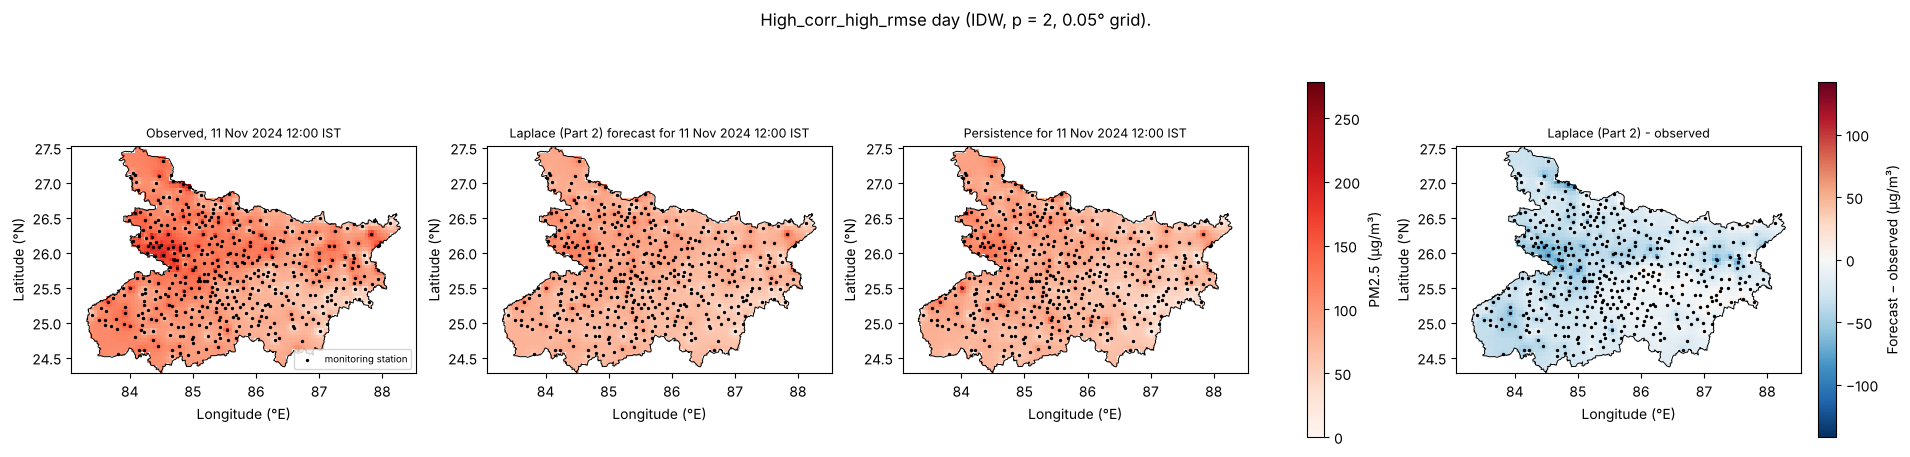

In [11]:
Mm_all, Om_all = idw(MODEL), idw(OBS)
ex = pd.DataFrame({"pattern corr": daily[MODEL_NAME].pattern_corr, "map RMSE": daily[MODEL_NAME].map_rmse,
                   "map bias (forecast - observed)": (Mm_all - Om_all).mean(axis=1),
                   "observed map mean": Om_all.mean(axis=1)}, index=dates)
display(ex[ex["pattern corr"] > 0.85].sort_values("map RMSE", ascending=False).head(3).round(2))
print(f"median pattern corr over all days: {ex['pattern corr'].median():.2f}; mean map RMSE: {ex['map RMSE'].mean():.2f}")
plot_day(pd.Timestamp("2024-11-11"), "high_corr_high_rmse")

## Answers 

**Which RMSE is better, map or station? Which to quote?**
For our model (Laplace, Part 2) the mean daily map RMSE is 13.84 µg/m³ against a mean daily station RMSE of 24.75 (overall station RMSE 28.16); for persistence 15.37 against 28.57 (overall 32.75). Map RMSE is about half the station RMSE: IDW is a smoothing average, so independent station-level errors partly cancel. That lower number is partly an artefact of interpolation, not better forecasting. Quote the **station RMSE** as forecast accuracy: it is checked against real readings and cannot be flattered by smoothing. Map RMSE is useful partcularly for judging the spatial picture.

**In what sense is the observed map not ground truth?**
It is an IDW interpolation of 468 point sensors: between stations it is just a distance-weighted average, so it cannot represent local values that lie between sensors. The sensors themselves are low-cost and some readings were gap-filled upstream, so even the station values are not exact. Therefore, the observed map is not the ground truth. We can measure how far off it is: leaving each station out and interpolating it from the other 467 gives an RMSE of 32.9 µg/m³ (correlation 0.81) on the validation targets, with the nearest other station a median 9 km away. That interpolation error is as large as the forecast errors being compared (28.2 for our model, 32.75 for persistence), so between stations the "observed" map is a weak yardstick.

**Describe a forecast that has a good pattern correlation but a poor RMSE. Good pattern correlation or poor RMSE, which matters more for a public warning?**
A forecast that gets the spatial *shape* right but the overall *level* wrong. Our own model on 11 Nov 2024 is an example: its map has a pattern correlation of 0.91 (median over all days 0.64), but a map RMSE of 29.6 µg/m³, about twice its average of 13.8, because it under-predicted almost everywhere by about 25 µg/m³ on a day with an observed mean of 102. For a public warning the **absolute level** matters more, because health advice and alert bands are tied to concentration thresholds.